In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
#for dirname, _, filenames in os.walk('/kaggle/input'):
#    for filename in filenames:
#        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# Setup

In [2]:
from pathlib import Path
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image
from IPython.display import display

def quality_metrics_for_paths(paths, max_images=100):
    candidates = paths.dropna()
    if len(candidates) > max_images:
        candidates = candidates.sample(max_images, random_state=42)
    rows = []
    for image_path in candidates:
        image_path = Path(image_path)
        if not image_path.is_file():
            continue
        try:
            with Image.open(image_path) as image_file:
                image = np.array(image_file.convert('L'))
            rows.append({
                'img_path': str(image_path),
                'width': width,
                'height': height,
                'aspect': width / height,
                'brightness': float(image.mean()),
                'contrast': float(image.std()),
                'sharpness': float(cv2.Laplacian(
                    image.astype(np.float32), cv2.CV_32F
                ).var()),
            })
        except (OSError, ValueError):
            continue
    return pd.DataFrame(rows)


KAGGLE_CHEXPERT_ROOT = Path('/kaggle/input/datasets/ashery/chexpert')
KAGGLE_NIH_ROOT = Path('/kaggle/input/datasets/nih-chest-xrays/data')
KAGGLE_CHEXPHOTO_ROOT = Path(
    '/kaggle/input/notebooks/t1f3001843/chexphoto-data-extraction/CheXphoto'
)

if Path('/kaggle/input').exists():
    if not KAGGLE_CHEXPERT_ROOT.exists():
        raise FileNotFoundError(f'CheXpert mount not found: {KAGGLE_CHEXPERT_ROOT}')
    if not KAGGLE_NIH_ROOT.exists():
        raise FileNotFoundError(f'NIH mount not found: {KAGGLE_NIH_ROOT}')
    if not KAGGLE_CHEXPHOTO_ROOT.exists():
        raise FileNotFoundError(f'CheXphoto mount not found: {KAGGLE_CHEXPHOTO_ROOT}')

    CHEXPERT_ROOT = KAGGLE_CHEXPERT_ROOT
    NIH_ROOT = KAGGLE_NIH_ROOT
    CHEXPHOTO_ROOT = KAGGLE_CHEXPHOTO_ROOT
    CHEXPERT_TRAIN_CSV = CHEXPERT_ROOT / 'train.csv'
    CHEXPERT_VALID_CSV = CHEXPERT_ROOT / 'valid.csv'
    NIH_LABELS_CSV = next(
        (
            candidate for candidate in [
                NIH_ROOT / 'Data_Entry_2017.csv',
                NIH_ROOT / 'sample_labels.csv',
            ] if candidate.exists()
        ),
        None,
    )
    NIH_BBOX_CSV = NIH_ROOT / 'BBox_List_2017.csv'
    CHEXPHOTO_METADATA_CSV = CHEXPHOTO_ROOT / 'frontal_metadata_1000.csv'
else:
    # Local fallback for testing outside Kaggle.
    DATA_ROOT = next(
        (p.resolve() for p in [Path.cwd() / 'data', Path.cwd().parent / 'data']
         if p.exists()),
        None,
    )
    if DATA_ROOT is None:
        raise FileNotFoundError('Expected a local data directory beside the notebook.')
    CHEXPERT_ROOT = DATA_ROOT / 'chexpert'
    NIH_ROOT = DATA_ROOT / 'nih'
    CHEXPHOTO_ROOT = DATA_ROOT / 'chexphoto'
    CHEXPERT_TRAIN_CSV = CHEXPERT_ROOT / 'train.csv'
    CHEXPERT_VALID_CSV = CHEXPERT_ROOT / 'valid.csv'
    NIH_LABELS_CSV = (
        NIH_ROOT / 'Data_Entry_2017.csv'
        if (NIH_ROOT / 'Data_Entry_2017.csv').exists()
        else NIH_ROOT / 'sample_labels.csv'
    )
    NIH_BBOX_CSV = NIH_ROOT / 'BBox_List_2017.csv'
    CHEXPHOTO_METADATA_CSV = next(
        (
            candidate for candidate in [
                CHEXPHOTO_ROOT / 'master_metadata.csv',
                CHEXPHOTO_ROOT / 'frontal_metadata_1000.csv',
            ] if candidate.exists()
        ),
        None,
    )

if not CHEXPERT_TRAIN_CSV.exists() or not CHEXPERT_VALID_CSV.exists():
    raise FileNotFoundError(
        f'CheXpert metadata is incomplete: {CHEXPERT_TRAIN_CSV}, '
        f'{CHEXPERT_VALID_CSV}'
    )
if NIH_LABELS_CSV is None or not NIH_LABELS_CSV.exists() or not NIH_BBOX_CSV.exists():
    raise FileNotFoundError(
        f'NIH metadata is incomplete: {NIH_LABELS_CSV}, {NIH_BBOX_CSV}'
    )
if CHEXPHOTO_METADATA_CSV is None or not CHEXPHOTO_METADATA_CSV.exists():
    raise FileNotFoundError(
        f'CheXphoto metadata not found: {CHEXPHOTO_METADATA_CSV}'
    )

OUTPUT_ROOT = (
    Path('/kaggle/working/outputs')
    if Path('/kaggle/working').exists()
    else Path.cwd() / 'outputs'
)
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

QUALITY_CSV = next(
    (
        candidate for candidate in [
            CHEXPHOTO_ROOT / 'image_quality_metrics.csv',
            CHEXPHOTO_ROOT.parent / 'image_quality_metrics.csv',
        ] if candidate.exists()
    ),
    Path('__image_quality_metrics_not_mounted__.csv'),
)

CHEXPERT_IMAGE_ROOTS = list(dict.fromkeys([
    CHEXPERT_ROOT,
    CHEXPERT_ROOT.parent,
    CHEXPERT_ROOT.parent.parent,
]))


def resolve_chexpert_path(csv_path):
    parts = str(csv_path).replace('\\', '/').split('/')
    split_index = next(
        (i for i, part in enumerate(parts) if part in {'train', 'valid'}),
        None,
    )
    if split_index is None:
        return None
    split = parts[split_index]
    suffix = Path(*parts[split_index + 1:])
    candidates = []
    for root in CHEXPERT_IMAGE_ROOTS:
        candidates.extend([
            root / split / suffix,
            root / 'CheXpert-v1.0-small' / split / suffix,
            root / 'chexpert-v1.0-small' / split / suffix,
            root / 'chexpert' / split / suffix,
        ])
    return next(
        (str(candidate) for candidate in candidates if candidate.is_file()),
        None,
    )


print('CheXpert root:', CHEXPERT_ROOT)
print('NIH root:', NIH_ROOT)
print('CheXphoto root:', CHEXPHOTO_ROOT)
print('CheXphoto metadata:', CHEXPHOTO_METADATA_CSV)
print('Outputs:', OUTPUT_ROOT)


CheXpert root: /kaggle/input/datasets/ashery/chexpert
NIH root: /kaggle/input/datasets/nih-chest-xrays/data
CheXphoto root: /kaggle/input/notebooks/t1f3001843/chexphoto-data-extraction/CheXphoto
CheXphoto metadata: /kaggle/input/notebooks/t1f3001843/chexphoto-data-extraction/CheXphoto/frontal_metadata_1000.csv
Outputs: /kaggle/working/outputs


## EDA: CheXpert

CheXpert rows after frontal filtering:


,split,rows,patients
0,train,191027,64534
1,valid,202,200


,train_positive,valid_positive,train_uncertain,train_missing
Enlarged Cardiomediastinum,9187,105,10286,156209
Cardiomegaly,23385,66,6707,153066
Lung Opacity,94211,117,4431,87334
Lung Lesion,7040,1,1108,182103
Edema,49675,42,11818,113619
Consolidation,12983,32,24381,134055
Pneumonia,4675,8,15981,168496
Atelectasis,29720,75,29863,130419
Pneumothorax,17693,7,2708,122803
Pleural Effusion,76899,64,9578,79251


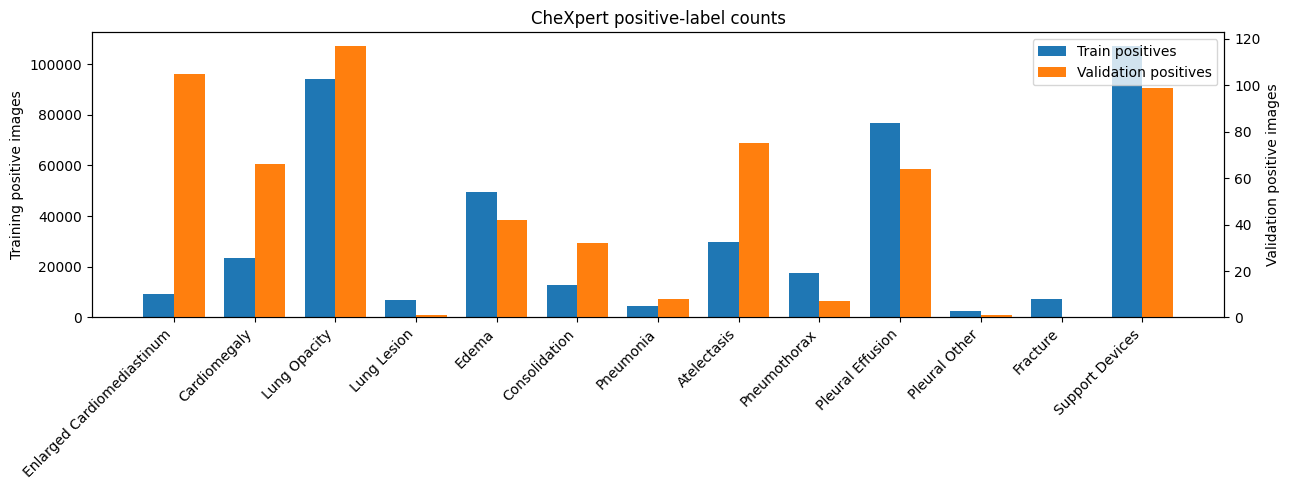

In [3]:
chexpert_train_raw = pd.read_csv(CHEXPERT_TRAIN_CSV)
chexpert_valid_raw = pd.read_csv(CHEXPERT_VALID_CSV)

chexpert_train = chexpert_train_raw[
    chexpert_train_raw['Frontal/Lateral'].eq('Frontal')
].copy()
chexpert_valid = chexpert_valid_raw[
    chexpert_valid_raw['Frontal/Lateral'].eq('Frontal')
].copy()

CHEXPERT_LABELS = [
    'Enlarged Cardiomediastinum', 'Cardiomegaly', 'Lung Opacity',
    'Lung Lesion', 'Edema', 'Consolidation', 'Pneumonia',
    'Atelectasis', 'Pneumothorax', 'Pleural Effusion',
    'Pleural Other', 'Fracture', 'Support Devices',
]

print('CheXpert rows after frontal filtering:')
display(pd.DataFrame({
    'split': ['train', 'valid'],
    'rows': [len(chexpert_train), len(chexpert_valid)],
    'patients': [
        chexpert_train['Path'].str.extract(r'(patient\d+)', expand=False).nunique(),
        chexpert_valid['Path'].str.extract(r'(patient\d+)', expand=False).nunique(),
    ],
}))

chexpert_prevalence = pd.DataFrame({
    'train_positive': (chexpert_train[CHEXPERT_LABELS] == 1).sum(),
    'valid_positive': (chexpert_valid[CHEXPERT_LABELS] == 1).sum(),
    'train_uncertain': (chexpert_train[CHEXPERT_LABELS] == -1).sum(),
    'train_missing': chexpert_train[CHEXPERT_LABELS].isna().sum(),
})
display(chexpert_prevalence)

labels = chexpert_prevalence.index
positions = np.arange(len(labels))
bar_width = 0.38
fig, train_ax = plt.subplots(figsize=(13, 5))
valid_ax = train_ax.twinx()
train_bars = train_ax.bar(
    positions - bar_width / 2,
    chexpert_prevalence['train_positive'],
    width=bar_width,
    color='tab:blue',
    label='Train positives',
)
valid_bars = valid_ax.bar(
    positions + bar_width / 2,
    chexpert_prevalence['valid_positive'],
    width=bar_width,
    color='tab:orange',
    label='Validation positives',
)
train_ax.set_title('CheXpert positive-label counts')
train_ax.set_ylabel('Training positive images')
valid_ax.set_ylabel('Validation positive images')
train_ax.set_xticks(positions)
train_ax.set_xticklabels(labels, rotation=45, ha='right')
train_ax.legend(
    [train_bars.patches[0], valid_bars.patches[0]],
    ['Train positives', 'Validation positives'],
    loc='upper right',
)
plt.tight_layout()
plt.show()

### CheXpert image-quality extremes

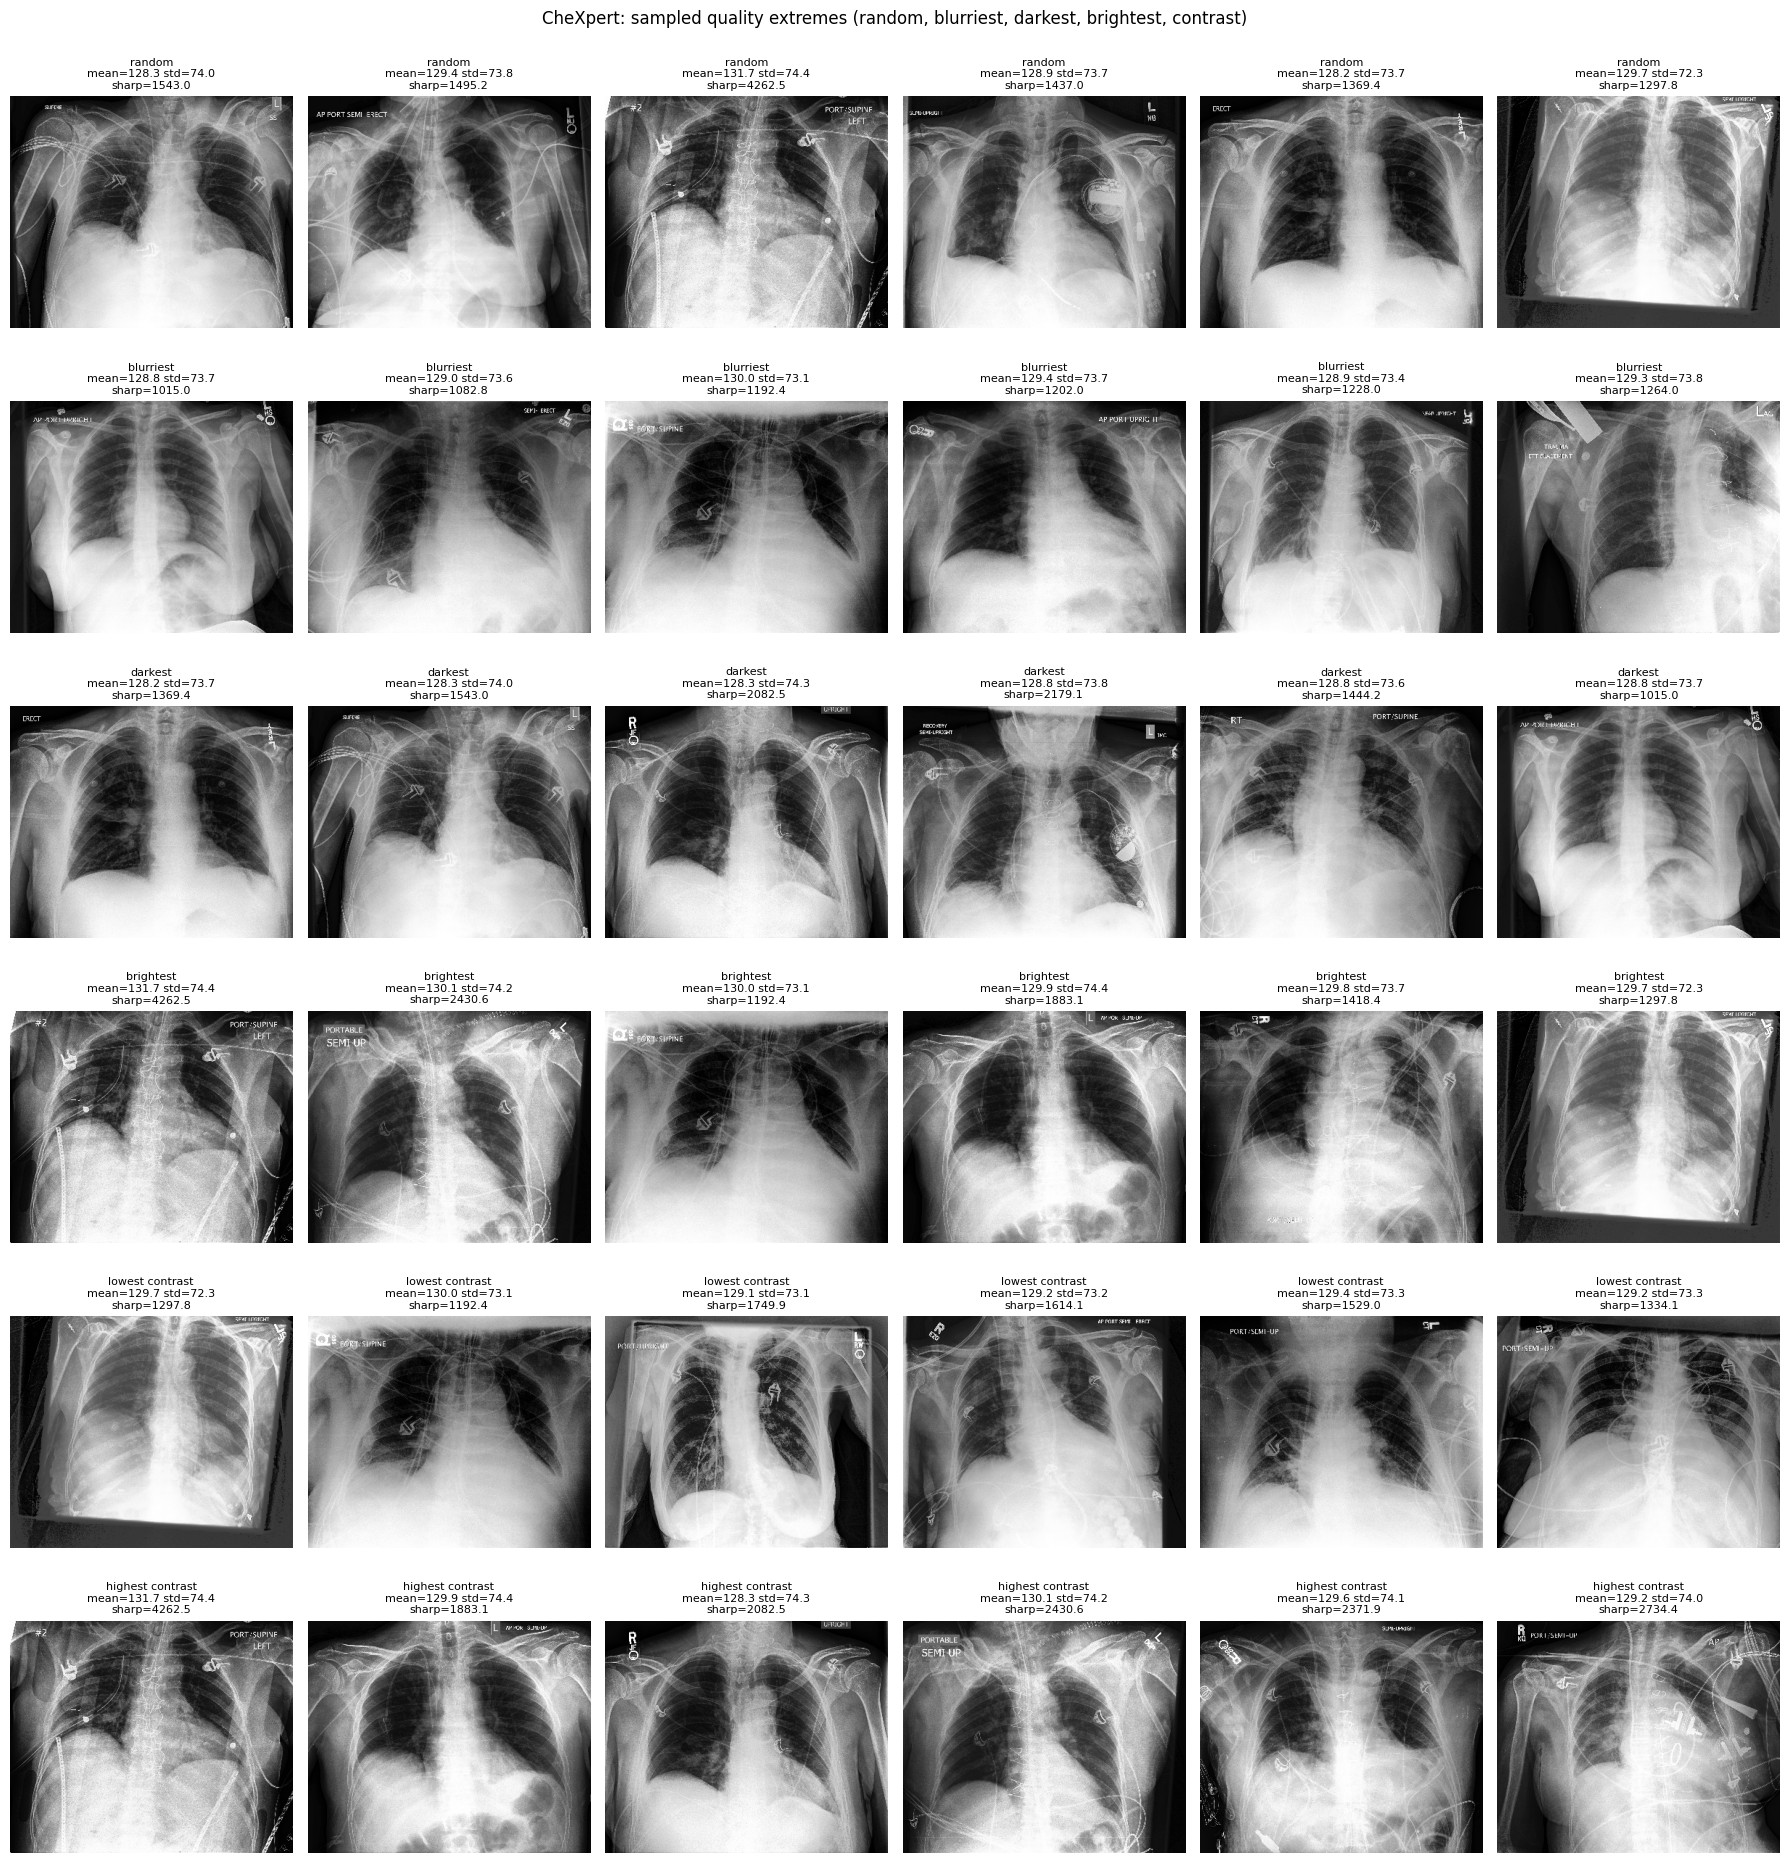

In [4]:
# --- Sampled quality metrics and visual extremes ---
def sampled_quality_metrics(paths, max_images=36):
    candidates = pd.Series(paths).dropna()
    if len(candidates) > max_images:
        candidates = candidates.sample(max_images, random_state=42)
    rows = []
    for path in candidates:
        path = Path(path)
        if not path.is_file():
            continue
        image = np.array(Image.open(path).convert('L'))
        rows.append({
            'img_path': str(path),
            'mean': float(image.mean()),
            'std': float(image.std()),
            'lap_var_common': float(cv2.Laplacian(
                image.astype(np.float32), cv2.CV_32F
            ).var()),
        })
    return pd.DataFrame(rows)


def sampled_extremes(metrics, source, title):
    if metrics.empty:
        print(f'No local images available for {source}.')
        return
    plan = [
        ('random', None, None),
        ('blurriest', 'lap_var_common', True),
        ('darkest', 'mean', True),
        ('brightest', 'mean', False),
        ('lowest contrast', 'std', True),
        ('highest contrast', 'std', False),
    ]
    fig, axes = plt.subplots(len(plan), 6, figsize=(18, 19))
    for row_index, (name, column, low) in enumerate(plan):
        if column is None:
            selected = metrics.sample(
                min(6, len(metrics)), random_state=42
            )
        elif low:
            selected = metrics.nsmallest(
                min(6, len(metrics)), column
            )
        else:
            selected = metrics.nlargest(
                min(6, len(metrics)), column
            )
        for axis, (_, record) in zip(axes[row_index], selected.iterrows()):
            axis.imshow(Image.open(record['img_path']).convert('L'), cmap='gray')
            axis.set_title(
                f'{name}\nmean={record["mean"]:.1f} '
                f'std={record["std"]:.1f}\n'
                f'sharp={record["lap_var_common"]:.1f}',
                fontsize=8,
            )
            axis.axis('off')
        for axis in axes[row_index][len(selected):]:
            axis.axis('off')
    plt.suptitle(
        f'{source}: sampled quality extremes '
        '(random, blurriest, darkest, brightest, contrast)',
        y=0.995,
    )
    plt.tight_layout()
    plt.show()


chexpert_sample = chexpert_train.sample(
    min(36, len(chexpert_train)), random_state=42
)
chexpert_quality = sampled_quality_metrics(
    chexpert_sample['Path'].map(resolve_chexpert_path),
    max_images=36,
)
sampled_extremes(chexpert_quality, 'CheXpert', 'CheXpert')


These examples show the range of acquisition quality present before preprocessing. Extreme brightness or contrast should not be mistaken for pathology, while low sharpness may represent a genuine robustness challenge.

CheXpert is the classifier-training source. Frontal-view filtering avoids mixing lateral views, while the uncertainty and missingness counts determine the loss policy. 

Patient IDs must be used for all train/validation splits.

## EDA: NIH labels and bounding boxes

In [5]:
nih = pd.read_csv(NIH_LABELS_CSV)
nih['Patient_ID'] = nih['Image Index'].str.extract(r'^(\d+)_', expand=False)
nih['Finding Count'] = nih['Finding Labels'].fillna('').str.count(r'\|') + 1

# The Kaggle NIH input has a fixed images_001 ... images_012 layout.
# Resolve only filenames present in the metadata instead of recursively walking
# every file in the dataset.
# Build one filename index per accessible image directory. This avoids
# repeatedly calling is_file() across every mounted directory for every row.
nih_image_directories = [
    *[
        NIH_ROOT / f'images_{index:03d}' / 'images'
        for index in range(1, 13)
    ],
    NIH_ROOT / 'sample' / 'images',
    NIH_ROOT / 'sample' / 'sample' / 'images',
    NIH_ROOT / 'images',
]

nih_image_index = {}
accessible_nih_directories = []
for directory in nih_image_directories:
    if not directory.is_dir():
        continue
    accessible_nih_directories.append(directory)
    try:
        with os.scandir(directory) as entries:
            for entry in entries:
                if entry.is_file():
                    nih_image_index.setdefault(
                        entry.name, str(Path(entry.path))
                    )
    except OSError as error:
        print(f'Could not read NIH image directory {directory}: {error}')

nih['img_path'] = nih['Image Index'].map(nih_image_index)
print(
    f'NIH image directories accessible: '
    f'{len(accessible_nih_directories)}/{len(nih_image_directories)}'
)
print(
    f'NIH image index entries: {len(nih_image_index):,}; '
    f'metadata paths resolved: {int(nih["img_path"].notna().sum()):,}/'
    f'{len(nih):,}'
)

nih_labels = sorted({
    label
    for value in nih['Finding Labels'].dropna()
    for label in str(value).split('|')
})
nih_label_counts = pd.Series({
    label: nih['Finding Labels'].fillna('').str.split('|').apply(
        lambda labels: label in labels
    ).sum()
    for label in nih_labels
}).sort_values(ascending=False)
display(pd.DataFrame({
    'images': [len(nih)],
    'patients': [nih['Patient_ID'].nunique()],
    'local_images': [nih['img_path'].notna().sum()],
}))
display(nih_label_counts.rename('positive_images').to_frame())

nih_boxes = pd.read_csv(
    NIH_BBOX_CSV,
    header=None,
    skiprows=1,
    names=['Image Index', 'Finding Label', 'x', 'y', 'w', 'h'],
)
for column in ['x', 'y', 'w', 'h']:
    nih_boxes[column] = pd.to_numeric(nih_boxes[column], errors='coerce')
nih_boxes = nih_boxes.dropna(
    subset=['Image Index', 'Finding Label', 'x', 'y', 'w', 'h']
).copy()
# Some Kaggle NIH metadata exports omit the original image dimensions.
# Only localized images need dimensions for this EDA and normalization step.
for dimension in ['OriginalImageWidth', 'OriginalImageHeight']:
    if dimension not in nih.columns:
        nih[dimension] = np.nan

nih['OriginalImageWidth'] = pd.to_numeric(
    nih['OriginalImageWidth'], errors='coerce'
)
nih['OriginalImageHeight'] = pd.to_numeric(
    nih['OriginalImageHeight'], errors='coerce'
)
bbox_image_names = set(nih_boxes['Image Index'].dropna())
needs_dimensions = (
    nih['Image Index'].isin(bbox_image_names)
    & nih['img_path'].notna()
    & (
        nih['OriginalImageWidth'].isna()
        | nih['OriginalImageHeight'].isna()
    )
)
print(
    f'Reading dimensions for {int(needs_dimensions.sum()):,} '
    f'localized images (not all {len(nih):,} metadata rows)...'
)
for index, row in nih.loc[needs_dimensions].iterrows():
    try:
        with Image.open(row['img_path']) as image:
            width, height = image.size
        nih.at[index, 'OriginalImageWidth'] = width
        nih.at[index, 'OriginalImageHeight'] = height
    except (OSError, ValueError):
        continue

nih_boxes = nih_boxes.merge(
    nih[['Image Index', 'Patient_ID', 'OriginalImageWidth',
         'OriginalImageHeight', 'img_path', 'Finding Labels']],
    on='Image Index',
    how='left',
    validate='many_to_one',
)
nih_boxes = nih_boxes.dropna(
    subset=['OriginalImageWidth', 'OriginalImageHeight']
).copy()
nih_boxes['in_local_sample'] = nih_boxes['img_path'].notna()
nih_boxes['x_norm'] = nih_boxes['x'] / nih_boxes['OriginalImageWidth']
nih_boxes['y_norm'] = nih_boxes['y'] / nih_boxes['OriginalImageHeight']
nih_boxes['w_norm'] = nih_boxes['w'] / nih_boxes['OriginalImageWidth']
nih_boxes['h_norm'] = nih_boxes['h'] / nih_boxes['OriginalImageHeight']

print('Bounding-box summary:')
display(nih_boxes.groupby('Finding Label').agg(
    boxes=('Image Index', 'size'),
    images=('Image Index', 'nunique'),
    local_boxes=('in_local_sample', 'sum'),
).sort_values('boxes', ascending=False))

NIH image directories accessible: 12/15
NIH image index entries: 112,120; metadata paths resolved: 112,120/112,120


,images,patients,local_images
0,112120,30805,112120


,positive_images
No Finding,60361
Infiltration,19894
Effusion,13317
Atelectasis,11559
Nodule,6331
Mass,5782
Pneumothorax,5302
Consolidation,4667
Pleural_Thickening,3385
Cardiomegaly,2776


Reading dimensions for 880 localized images (not all 112,120 metadata rows)...
Bounding-box summary:


,boxes,images,local_boxes
Finding Label,,,
Atelectasis,180,180,180
Effusion,153,153,153
Cardiomegaly,146,146,146
Infiltrate,123,123,123
Pneumonia,120,120,120
Pneumothorax,98,98,98
Mass,85,85,85
Nodule,79,79,79


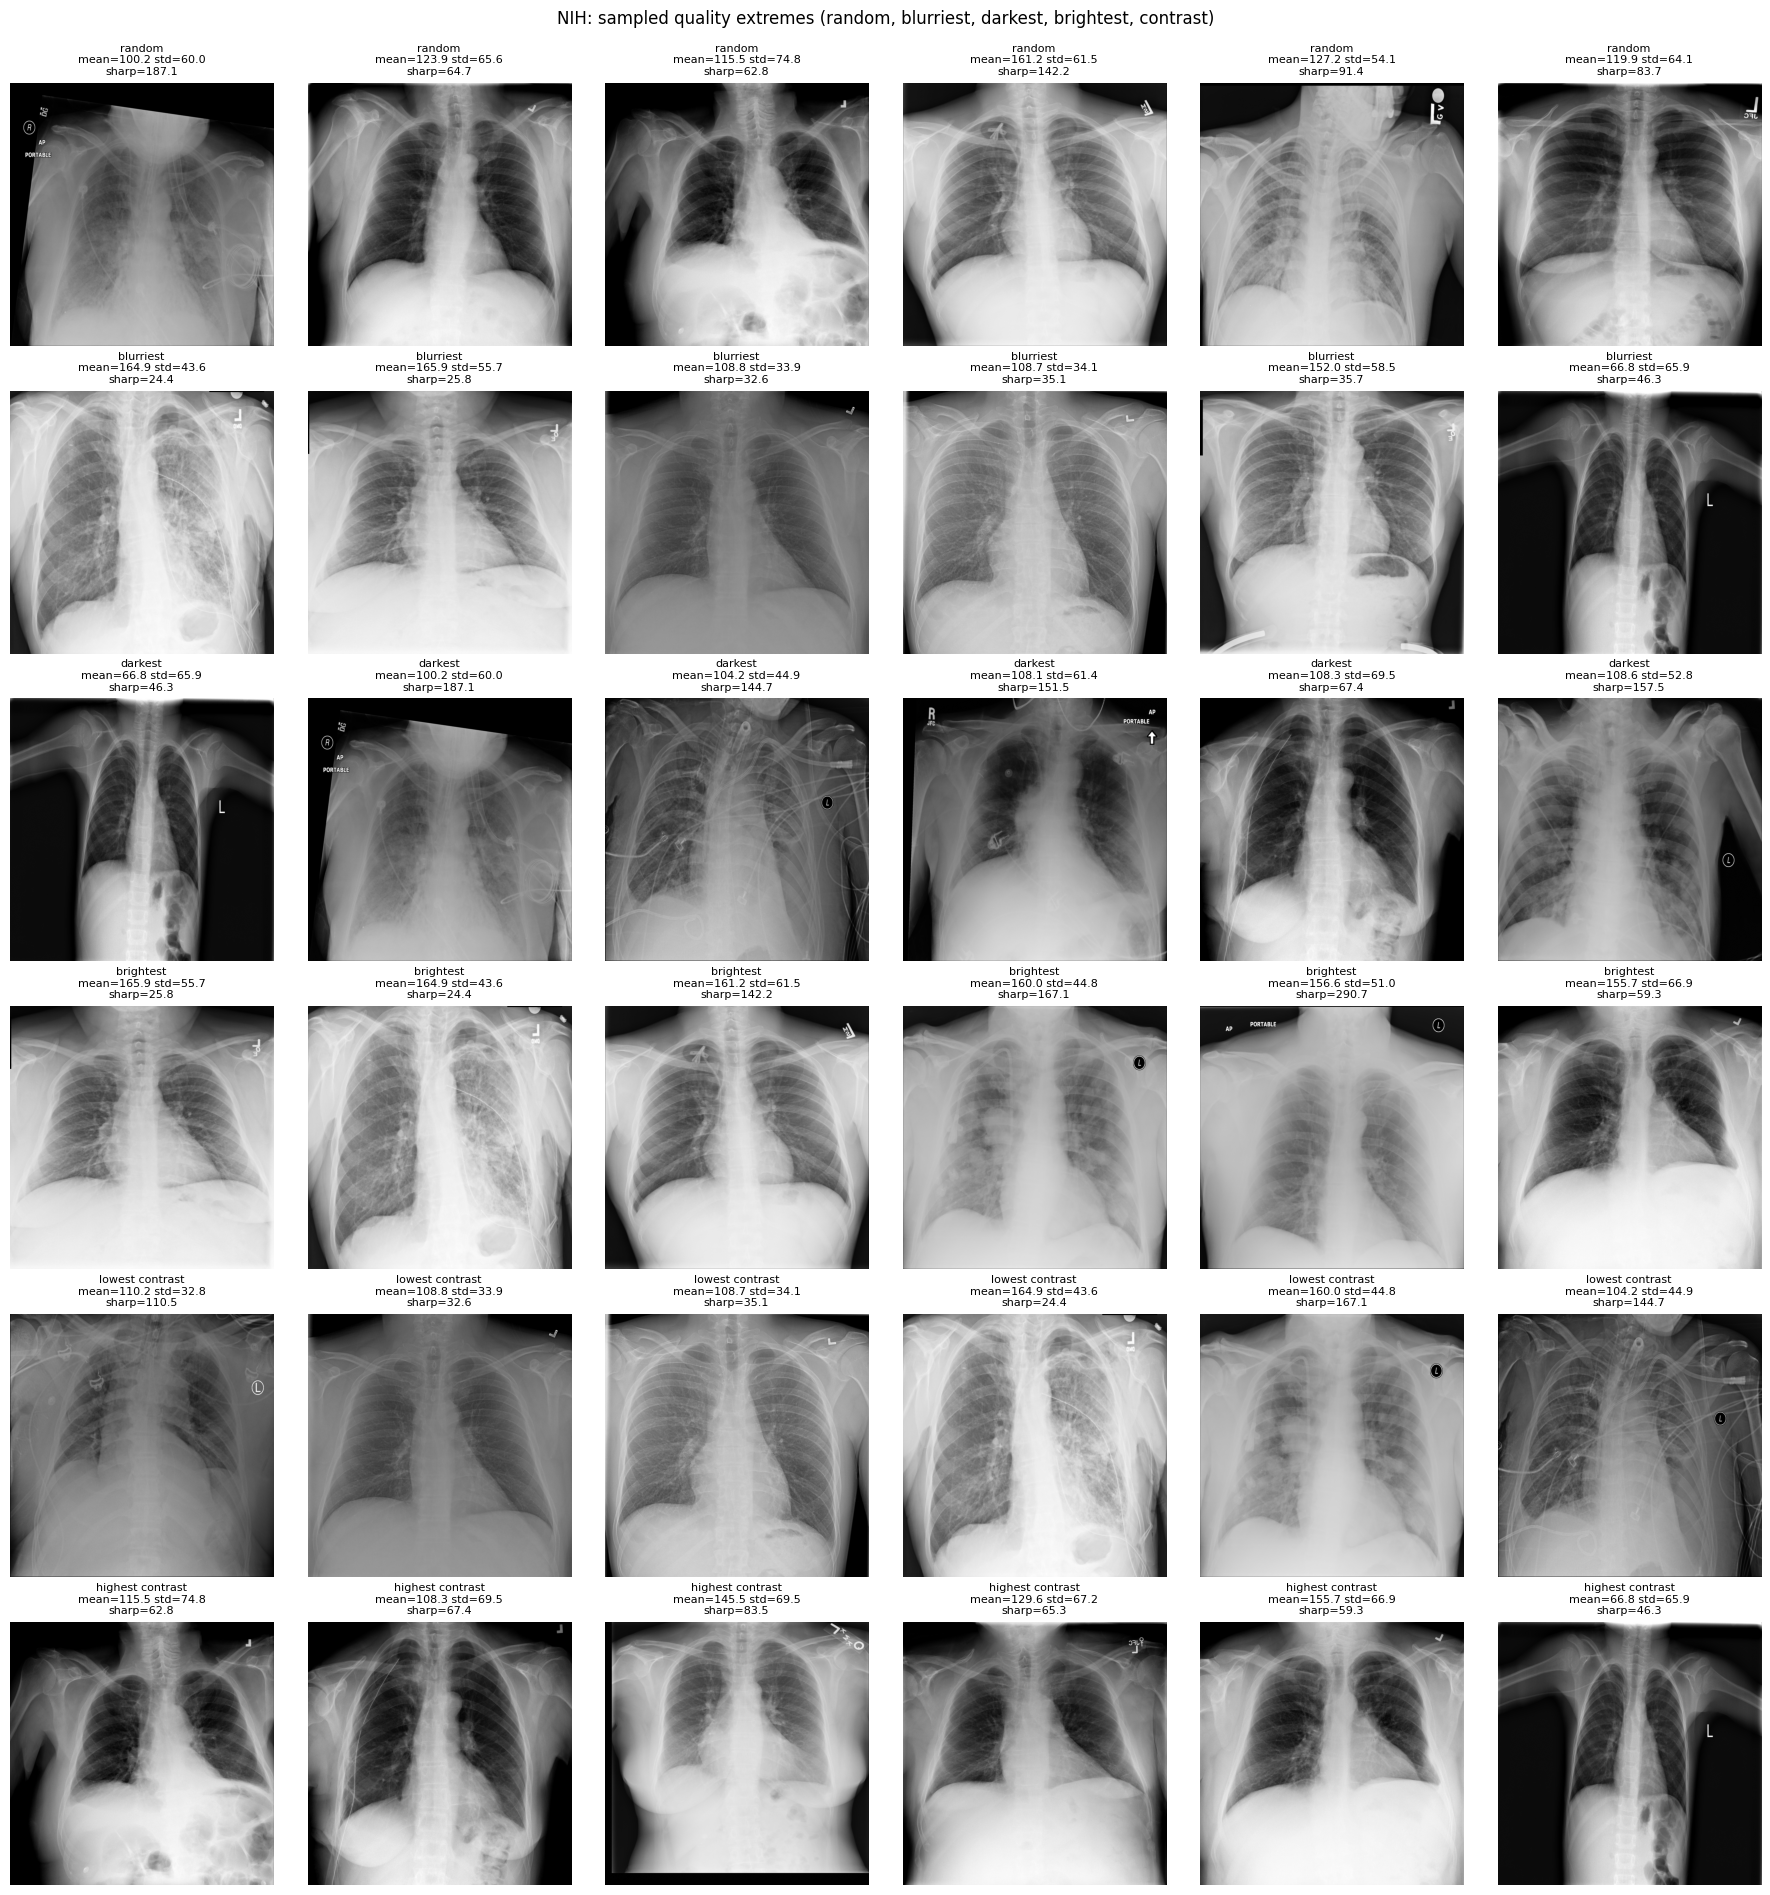

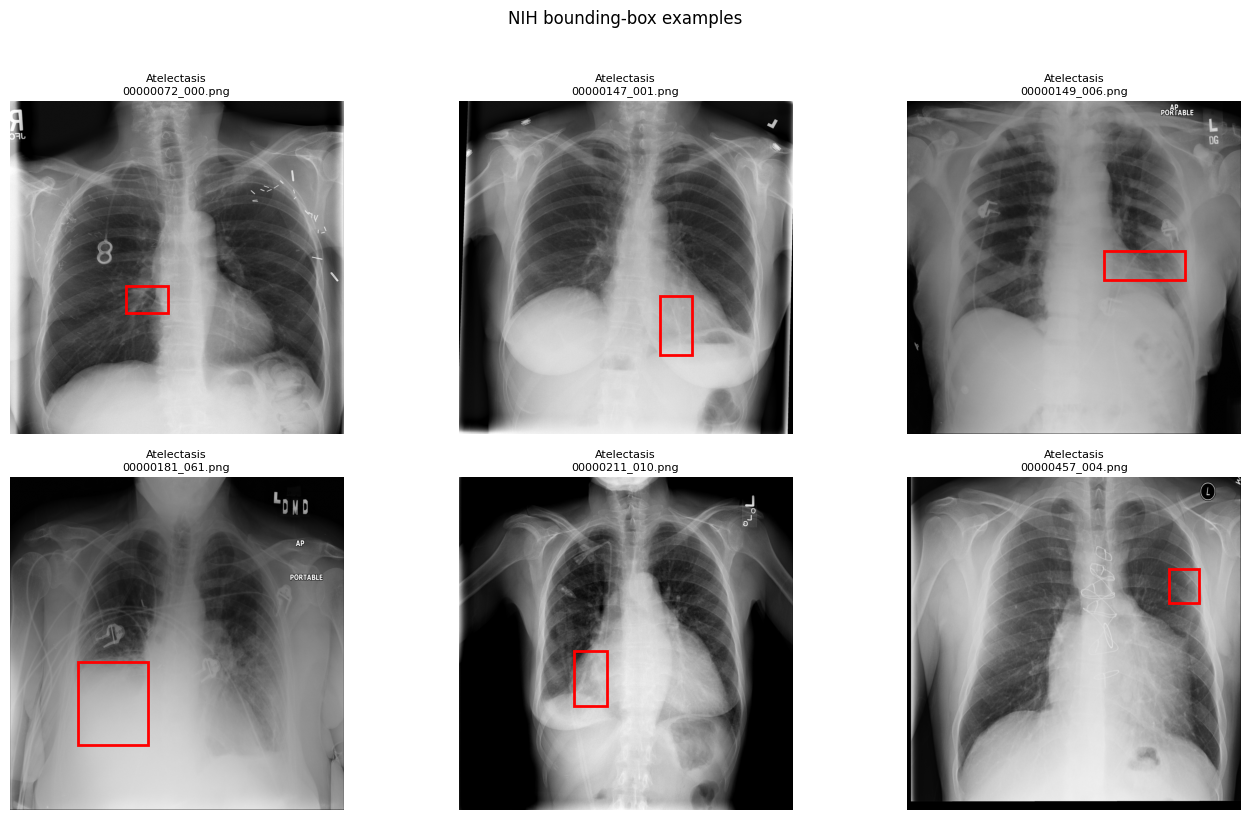

In [6]:
# --- NIH sampled quality extremes and bounding-box examples ---
nih_quality = sampled_quality_metrics(
    nih.sample(min(36, len(nih)), random_state=42)['img_path'],
    max_images=36,
)
sampled_extremes(nih_quality, 'NIH', 'NIH')

nih_box_preview = (
    nih_boxes[nih_boxes['img_path'].notna()]
    .sort_values(['Finding Label', 'Image Index'])
    .drop_duplicates('Image Index')
    .head(6)
)
if not nih_box_preview.empty:
    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    for axis, (_, record) in zip(axes.flat, nih_box_preview.iterrows()):
        image = np.array(Image.open(record['img_path']).convert('L'))
        axis.imshow(image, cmap='gray')
        axis.add_patch(plt.Rectangle(
            (record['x'], record['y']),
            record['w'],
            record['h'],
            fill=False,
            color='red',
            linewidth=2,
        ))
        axis.set_title(
            f'{record["Finding Label"]}\n{record["Image Index"]}',
            fontsize=8,
        )
        axis.axis('off')
    for axis in axes.flat[len(nih_box_preview):]:
        axis.axis('off')
    plt.suptitle('NIH bounding-box examples', y=1.02)
    plt.tight_layout()
    plt.show()


This visualization shows NIH images with the lowest and highest brightness, contrast, and sharpness, followed by annotated images with their ground-truth boxes.

NIH boxes identify the region used for localization supervision. Their placement and size must be transformed together with the image; otherwise, fine-tuning targets would no longer align with the anatomy

NIH supplies the localization supervision. Bounding boxes are joined by image ID, normalized using the original dimensions, and restricted to locally available images before training.

## CheXPhoto

In [7]:
chexphoto = pd.read_csv(CHEXPHOTO_METADATA_CSV)
photo_path_column = next(
    column for column in [
        'downloaded_filename', 'file_path', 'original_relative_path', 'Path'
    ] if column in chexphoto.columns
)


def resolve_chexphoto_path(row):
    value = Path(str(row[photo_path_column]))
    filename = value.name
    candidates = [
        value if value.is_absolute() else None,
        CHEXPHOTO_ROOT / 'grayscale' / filename,
        CHEXPHOTO_ROOT / 'originals' / str(row.get('split', '')) / filename,
        CHEXPHOTO_ROOT / 'train' / filename,
        CHEXPHOTO_ROOT / 'valid' / filename,
        CHEXPHOTO_ROOT / value,
    ]
    return next(
        (str(candidate) for candidate in candidates
         if candidate is not None and candidate.is_file()),
        None,
    )


chexphoto['img_path'] = chexphoto.apply(resolve_chexphoto_path, axis=1)
row_text = chexphoto.apply(
    lambda row: ' '.join(map(str, row.tolist())), axis=1
).str.lower()
chexphoto['acquisition_type'] = np.select(
    [
        row_text.str.contains('photographic', na=False),
        row_text.str.contains('digital', na=False),
    ],
    ['photographic', 'digital'],
    default='unknown',
)

print('CheXphoto inventory:')
display(chexphoto.groupby(
    ['acquisition_type', 'split'], dropna=False
).agg(
    images=('img_path', 'size'),
    local_images=('img_path', lambda values: values.notna().sum()),
))

PHOTO_LABELS = [
    column for column in [
        'Pleural_Effusion', 'Cardiomegaly', 'Pneumothorax',
        'Atelectasis', 'Consolidation', 'Lung_Lesion',
    ] if column in chexphoto.columns
]
if PHOTO_LABELS:
    display(chexphoto.groupby('acquisition_type')[PHOTO_LABELS]
            .apply(lambda frame: (frame == 1).sum()))

if QUALITY_CSV.exists():
    quality = pd.read_csv(QUALITY_CSV)
    if 'downloaded_filename' in quality.columns:
        chexphoto_quality = chexphoto.merge(
            quality, on='downloaded_filename', how='left',
            suffixes=('', '_quality')
        )
        quality_columns = [
            column for column in [
                'brightness', 'contrast', 'blur_score',
                'dark_fraction', 'bright_fraction'
            ] if column in chexphoto_quality.columns
        ]
        if quality_columns:
            display(chexphoto_quality.groupby('acquisition_type')
                    [quality_columns].median(numeric_only=True).round(3))


CheXphoto inventory:


images  local_images
acquisition_type split                      
digital          train     324           324
                 valid       4             4
photographic     train     297           297
                 valid       5             5
unknown          train     365           365
                 valid       5             5

,Pleural_Effusion,Cardiomegaly,Pneumothorax,Atelectasis,Consolidation,Lung_Lesion
acquisition_type,,,,,,
digital,128,47,29,46,23,5
photographic,122,33,21,52,18,14
unknown,153,49,42,53,26,9


,brightness,contrast,blur_score,dark_fraction,bright_fraction
acquisition_type,,,,,
digital,108.784,67.233,199.853,0.028,0.000
photographic,115.629,79.452,214.127,0.116,0.016
unknown,87.666,73.520,2517.240,0.003,0.007


The paired display compares digital and photographed images using the same metadata sample where possible. It is intended to make glare, blur, framing, and exposure differences visible before preprocessing.

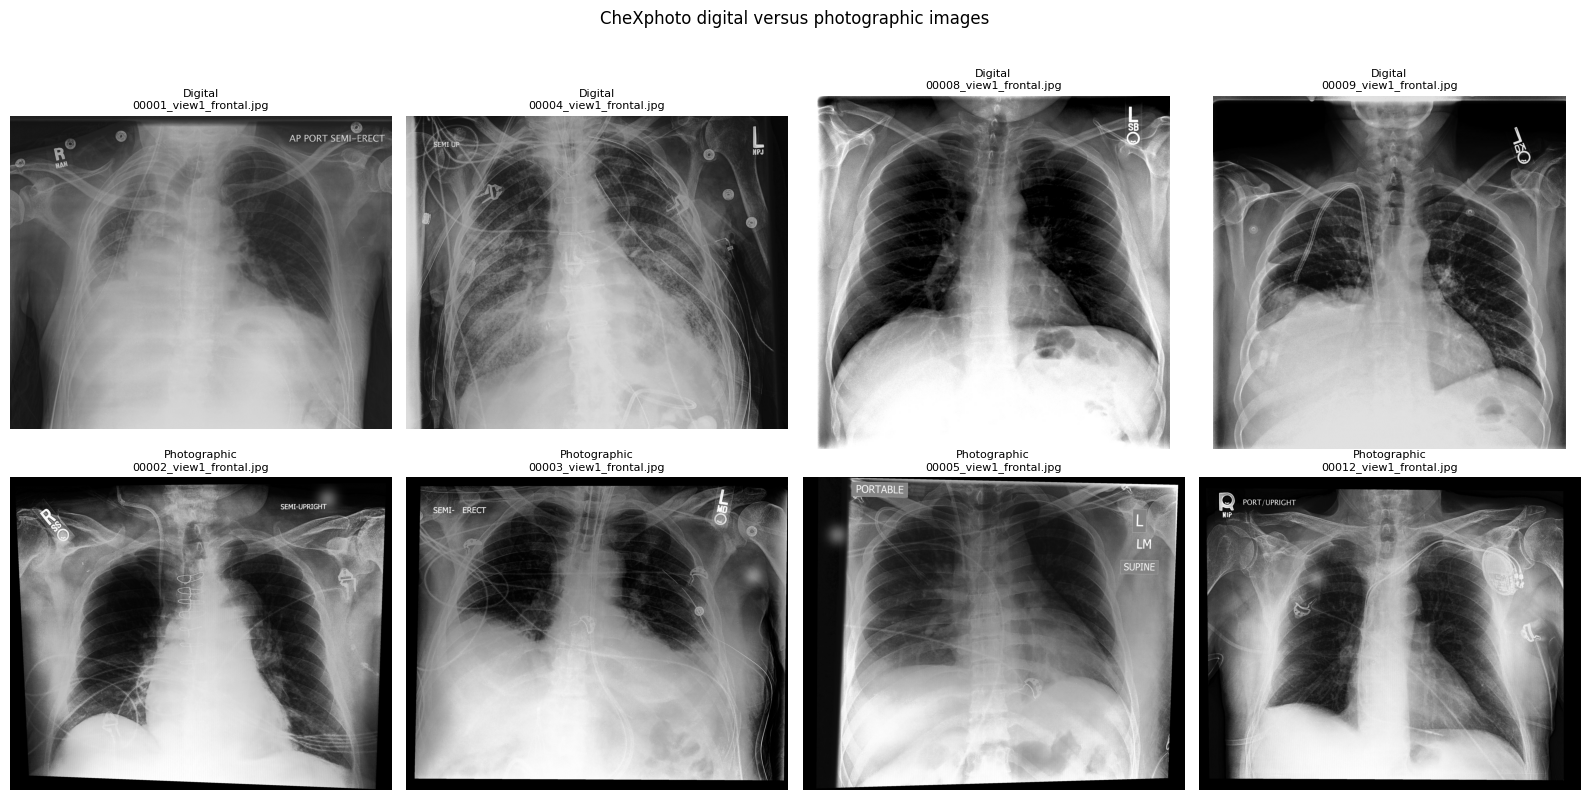

,brightness,contrast,sharpness
acquisition_type,,,
digital,107.54,66.94,166.25
photographic,115.95,79.16,225.31
unknown,86.66,74.17,3411.18


In [8]:
def first_existing(frame, count=4):
    return frame[frame['img_path'].notna()].drop_duplicates(
        'img_path'
    ).head(count)


digital_examples = first_existing(
    chexphoto[chexphoto['acquisition_type'].eq('digital')]
)
photographic_examples = first_existing(
    chexphoto[chexphoto['acquisition_type'].eq('photographic')]
)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (_, row) in zip(axes[0], digital_examples.iterrows()):
    ax.imshow(Image.open(row['img_path']).convert('L'), cmap='gray')
    ax.set_title(f"Digital\n{Path(row['img_path']).name}", fontsize=8)
    ax.axis('off')
for ax, (_, row) in zip(axes[1], photographic_examples.iterrows()):
    ax.imshow(Image.open(row['img_path']).convert('L'), cmap='gray')
    ax.set_title(f"Photographic\n{Path(row['img_path']).name}", fontsize=8)
    ax.axis('off')
for ax in list(axes[0])[len(digital_examples):] + list(axes[1])[len(photographic_examples):]:
    ax.axis('off')
plt.suptitle('CheXphoto digital versus photographic images', y=1.02)
plt.tight_layout()
plt.show()

photo_quality = quality_metrics_for_paths(chexphoto['img_path'], max_images=200)
if not photo_quality.empty:
    photo_quality = photo_quality.merge(
        chexphoto[['img_path', 'acquisition_type']].drop_duplicates(),
        on='img_path',
        how='left',
    )
    display(photo_quality.groupby('acquisition_type')[
        ['brightness', 'contrast', 'sharpness']
    ].median().round(2))


The photographic subset is the intended external robustness test. Differences in glare, blur, framing, and contrast are expected and should remain visible in at least one evaluation baseline rather than being fully normalized away.

CheXphoto is reserved for external robustness testing. Photographic images are identified from acquisition metadata/path information, while unknown acquisition types remain explicitly flagged rather than silently assigned to training.

## Cross-dataset EDA: low-level domain shift

In [9]:
def image_metrics(path, max_side=512):
    with Image.open(path) as image_file:
        width, height = image_file.size
        image_file = image_file.convert('L')
        image_file.thumbnail((max_side, max_side))
        image = np.asarray(image_file)
    return {
        'width': width,
        'height': height,
        'aspect': width / height,
        'brightness': float(image.mean()),
        'contrast': float(image.std()),
        'sharpness': float(cv2.Laplacian(
            image.astype(np.float32), cv2.CV_32F
        ).var()),
    }

metric_rows = []
source_frames = {
    'CheXpert': chexpert_train,
    'NIH': nih[nih['img_path'].notna()],
    'CheXphoto': chexphoto[chexphoto['img_path'].notna()],
}
source_path_columns = {
    'CheXpert': 'Path',
    'NIH': 'img_path',
    'CheXphoto': 'img_path',
}
max_images_per_source = 40
for source, frame in source_frames.items():
    paths = frame[source_path_columns[source]].dropna()
    if source == 'CheXpert':
        paths = paths.head(max_images_per_source).map(resolve_chexpert_path)
    else:
        paths = paths.head(max_images_per_source)
    paths = [
        value for value in paths
        if isinstance(value, str) and Path(value).is_file()
    ]
    print(f'Reading {len(paths)} {source} images for cross-dataset EDA...')
    for image_path in paths:
        try:
            row = image_metrics(image_path)
        except (OSError, ValueError):
            continue
        row['source'] = source
        metric_rows.append(row)

cross_metrics = pd.DataFrame(metric_rows)
display(cross_metrics.groupby('source').median(numeric_only=True).round(2))


Reading 40 CheXpert images for cross-dataset EDA...
Reading 40 NIH images for cross-dataset EDA...
Reading 40 CheXphoto images for cross-dataset EDA...


,width,height,aspect,brightness,contrast,sharpness
source,,,,,,
CheXpert,390.0,320.0,1.22,129.33,73.90,1438.11
CheXphoto,2828.0,2320.0,1.22,107.47,70.27,257.90
NIH,1024.0,1024.0,1.00,126.29,65.61,86.58


Domain-shift metrics are diagnostic rather than failure criteria.

## Common Pre-processing design

In [10]:
IMAGE_SIZE = 224

def percentile_normalize(image, low=1, high=99):
    image = image.astype(np.float32)
    lower, upper = np.percentile(image, [low, high])
    if upper <= lower:
        return np.zeros_like(image, dtype=np.uint8)
    return np.clip(
        (image - lower) * 255.0 / (upper - lower), 0, 255
    ).astype(np.uint8)

def resize_reflect_pad(image, size=IMAGE_SIZE):
    height, width = image.shape
    scale = min(size / width, size / height)
    new_width = max(1, round(width * scale))
    new_height = max(1, round(height * scale))
    resized = cv2.resize(
        image, (new_width, new_height), interpolation=cv2.INTER_AREA
    )
    left = (size - new_width) // 2
    right = size - new_width - left
    top = (size - new_height) // 2
    bottom = size - new_height - top
    return cv2.copyMakeBorder(
        resized, top, bottom, left, right, cv2.BORDER_REFLECT_101
    )

def preprocess_common(path, normalize=True):
    image = np.array(Image.open(path).convert('L'), dtype=np.uint8)
    if normalize:
        image = percentile_normalize(image)
    return resize_reflect_pad(image)

def image_to_tensor_array(path, normalize=True):
    return preprocess_common(path, normalize).astype(np.float32) / 255.0

The spatial transform is shared across datasets to avoid encoding dataset identity through preprocessing. It preserves aspect ratio, uses reflection padding rather than black padding, and clips extreme intensities before scaling. CheXphoto is not histogram-equalized by default because photographic glare, blur, and exposure variation are part of the robustness challenge.

Percentile clipping limits scanner and exposure outliers; aspect-preserving resize avoids anatomical distortion; reflection padding removes the strong black-border shortcut; scaling to `[0, 1]` makes the output ready for a neural-network input tensor.

## ChexPert Pre-processing pipeline

In [11]:
CHEXPERT_SHARED_LABELS = {
    'Pleural Effusion': 'Pleural Effusion',
    'Cardiomegaly': 'Cardiomegaly',
    'Pneumothorax': 'Pneumothorax',
    'Atelectasis': 'Atelectasis',
    'Consolidation': 'Consolidation',
    'Lung Lesion': 'Lung Lesion',
}

chexpert_image_path = resolve_chexpert_path

chexpert_manifest = pd.concat([
    chexpert_train.assign(split='train'),
    chexpert_valid.assign(split='valid'),
], ignore_index=True)
chexpert_manifest['img_path'] = (
    chexpert_manifest['Path'].map(chexpert_image_path)
)
chexpert_manifest = chexpert_manifest[
    chexpert_manifest['img_path'].notna()
].copy()
chexpert_manifest['patient_id'] = (
    chexpert_manifest['Path'].str.extract(
        r'(patient\d+)', expand=False
    )
)
chexpert_manifest.to_csv(
    OUTPUT_ROOT / 'chexpert_preprocessing_manifest.csv', index=False
)
print('CheXpert usable rows:', len(chexpert_manifest))
print('CheXpert missing local images:', chexpert_manifest['img_path'].isna().sum())

CheXpert usable rows: 191229
CheXpert missing local images: 0


This pipeline creates the classifier-training manifest, retains the original uncertainty values, and excludes only files that are unavailable locally. Uncertain labels should be handled by the model loss policy (`ignore`, `zeros`, or `ones`) rather than silently rewritten here.

## NIH localiztion Pre-Processing pipeline

In [12]:
NIH_TO_SHARED = {
    'Effusion': 'Pleural Effusion',
    'Cardiomegaly': 'Cardiomegaly',
    'Pneumothorax': 'Pneumothorax',
    'Atelectasis': 'Atelectasis',
    'Consolidation': 'Consolidation',
    'Mass': 'Lung Lesion',
    'Nodule': 'Lung Lesion',
}
nih_localization_manifest = nih_boxes.copy()
nih_localization_manifest['shared_label'] = (
    nih_localization_manifest['Finding Label'].map(NIH_TO_SHARED)
)
nih_localization_manifest = nih_localization_manifest[
    nih_localization_manifest['shared_label'].notna()
    & nih_localization_manifest['img_path'].notna()
].copy()
nih_localization_manifest.to_csv(
    OUTPUT_ROOT / 'nih_localization_preprocessing_manifest.csv',
    index=False,
)

def transform_box(row, size=IMAGE_SIZE):
    image_width = float(row['OriginalImageWidth'])
    image_height = float(row['OriginalImageHeight'])
    scale = min(size / image_width, size / image_height)
    pad_x = (size - image_width * scale) / 2
    pad_y = (size - image_height * scale) / 2
    return pd.Series({
        'box_x': row['x'] * scale + pad_x,
        'box_y': row['y'] * scale + pad_y,
        'box_w': row['w'] * scale,
        'box_h': row['h'] * scale,
    })

if not nih_localization_manifest.empty:
    transformed_boxes = nih_localization_manifest.apply(
        transform_box, axis=1
    )
    nih_localization_manifest = pd.concat(
        [nih_localization_manifest, transformed_boxes], axis=1
    )
display(nih_localization_manifest.groupby('shared_label').agg(
    boxes=('Image Index', 'size'),
    images=('Image Index', 'nunique'),
    patients=('Patient_ID', 'nunique'),
))

,boxes,images,patients
shared_label,,,
Atelectasis,180,180,167
Cardiomegaly,146,146,128
Lung Lesion,164,164,153
Pleural Effusion,153,153,142
Pneumothorax,98,98,82


Bounding boxes are converted to the shared label space and transformed with the same scale and padding used for the image. This preserves the box-to-image correspondence required for localization fine-tuning.

## CheXphoto external-test preprocessing pipeline

In [13]:
chexphoto_external = chexphoto[
    chexphoto['acquisition_type'].eq('photographic')
    & chexphoto['img_path'].notna()
].copy()
chexphoto_external['processed_path'] = chexphoto_external['img_path'].map(
    lambda path: str(
        OUTPUT_ROOT / 'chexphoto_processed' /
        (Path(path).stem + '.npy')
    )
)
chexphoto_external.to_csv(
    OUTPUT_ROOT / 'chexphoto_external_preprocessing_manifest.csv',
    index=False,
)
print('Photographic CheXphoto external rows:', len(chexphoto_external))
print('Unknown acquisition rows excluded:',
      int(chexphoto['acquisition_type'].eq('unknown').sum()))

Photographic CheXphoto external rows: 302
Unknown acquisition rows excluded: 370


Photographic acquisition artifacts are the target robustness challenge, so this pipeline uses the common grayscale, percentile, aspect-preserving, reflection-padded transform without aggressive equalization or denoising. CheXphoto remains test-only and is never added to the CheXpert training manifest.

## Pre-Processing validation

In [14]:
validation_rows = []
validation_sources = {
    'CheXpert': chexpert_manifest['img_path'].dropna().head(12),
    'NIH': nih_localization_manifest['img_path'].dropna().drop_duplicates().head(12),
    'CheXphoto': chexphoto_external['img_path'].dropna().head(12),
}

for dataset, paths in validation_sources.items():
    for image_path in paths:
        array = image_to_tensor_array(image_path)
        validation_rows.append({
            'dataset': dataset,
            'path': image_path,
            'shape': tuple(array.shape),
            'dtype': str(array.dtype),
            'min': float(array.min()),
            'max': float(array.max()),
            'finite': bool(np.isfinite(array).all()),
        })

preprocessing_validation = pd.DataFrame(validation_rows)
display(preprocessing_validation.groupby('dataset').agg(
    samples=('path', 'size'),
    shapes=('shape', lambda values: sorted(set(map(str, values)))),
    dtypes=('dtype', lambda values: sorted(set(values))),
    minimum=('min', 'min'),
    maximum=('max', 'max'),
    all_finite=('finite', 'all'),
))

if not preprocessing_validation.empty:
    assert preprocessing_validation['shape'].map(
        lambda shape: shape == (IMAGE_SIZE, IMAGE_SIZE)
    ).all()
    assert preprocessing_validation['dtype'].eq('float32').all()
    assert preprocessing_validation['min'].between(0, 1).all()
    assert preprocessing_validation['max'].between(0, 1).all()
    assert preprocessing_validation['finite'].all()

for manifest_name, manifest in {
    'CheXpert': chexpert_manifest,
    'NIH': nih_localization_manifest,
    'CheXphoto': chexphoto_external,
}.items():
    assert manifest['img_path'].map(Path).map(Path.is_file).all(), (
        f'{manifest_name} contains an unreadable image path'
    )

print('Tensor, range, dtype, finiteness, and manifest path checks passed.')


,samples,shapes,dtypes,minimum,maximum,all_finite
dataset,,,,,,
CheXpert,12,"[(224, 224)]",[float32],0.0,1.0,True
CheXphoto,12,"[(224, 224)]",[float32],0.0,1.0,True
NIH,12,"[(224, 224)]",[float32],0.0,1.0,True


Tensor, range, dtype, finiteness, and manifest path checks passed.


In [15]:
box_columns = ['box_x', 'box_y', 'box_w', 'box_h']
if not nih_localization_manifest.empty:
    box_values = nih_localization_manifest[box_columns].to_numpy()
    assert np.isfinite(box_values).all()
    assert (
        nih_localization_manifest['box_x'].ge(0)
        & nih_localization_manifest['box_y'].ge(0)
        & nih_localization_manifest['box_w'].gt(0)
        & nih_localization_manifest['box_h'].gt(0)
        & (
            nih_localization_manifest['box_x']
            + nih_localization_manifest['box_w']
        ).le(IMAGE_SIZE)
        & (
            nih_localization_manifest['box_y']
            + nih_localization_manifest['box_h']
        ).le(IMAGE_SIZE)
    ).all()

nih_box_check = nih_localization_manifest[
    nih_localization_manifest['img_path'].notna()
].copy()
nih_box_check['box_within_image'] = (
    nih_box_check['box_x'].ge(0)
    & nih_box_check['box_y'].ge(0)
    & (nih_box_check['box_x'] + nih_box_check['box_w']).le(IMAGE_SIZE)
    & (nih_box_check['box_y'] + nih_box_check['box_h']).le(IMAGE_SIZE)
)
display(pd.DataFrame({
    'check': [
        'Transformed boxes are finite',
        'Transformed boxes stay inside 224x224',
        'All NIH localization rows have shared labels',
    ],
    'result': [
        bool(np.isfinite(
            nih_localization_manifest[box_columns].to_numpy()
        ).all()) if not nih_localization_manifest.empty else True,
        bool(nih_box_check['box_within_image'].all())
        if not nih_box_check.empty else True,
        bool(nih_localization_manifest['shared_label'].notna().all()),
    ],
}))
print('NIH transformed bounding-box checks passed.')


,check,result
0,Transformed boxes are finite,True
1,Transformed boxes stay inside 224x224,True
2,All NIH localization rows have shared labels,True


NIH transformed bounding-box checks passed.


In [16]:
chexpert_train_patients = set(
    chexpert_train['Path'].str.extract(
        r'(patient\d+)', expand=False
    ).dropna()
)
chexpert_valid_patients = set(
    chexpert_valid['Path'].str.extract(
        r'(patient\d+)', expand=False
    ).dropna()
)
chexpert_overlap = chexpert_train_patients & chexpert_valid_patients

duplicate_checks = pd.DataFrame({
    'check': [
        'CheXpert train/valid patient overlap',
        'Duplicate CheXpert manifest paths',
        'Duplicate NIH localization image paths',
        'Unknown CheXphoto acquisition in external set',
    ],
    'value': [
        len(chexpert_overlap),
        int(chexpert_manifest['img_path'].duplicated().sum()),
        int(nih_localization_manifest['img_path'].duplicated().sum()),
        int(chexphoto_external['acquisition_type'].eq('unknown').sum()),
    ],
})
display(duplicate_checks)
assert not chexpert_overlap
assert duplicate_checks.loc[
    duplicate_checks['check'] == 'Unknown CheXphoto acquisition in external set',
    'value',
].iat[0] == 0
print(
    'CheXpert patient split and CheXphoto external-set checks passed. '
)


,check,value
0,CheXpert train/valid patient overlap,0
1,Duplicate CheXpert manifest paths,0
2,Duplicate NIH localization image paths,49
3,Unknown CheXphoto acquisition in external set,0


CheXpert patient split and CheXphoto external-set checks passed. 


,mean,std,near_zero_fraction,near_one_fraction
dataset,,,,
CheXpert,0.4988,0.3015,0.0189,0.0137
CheXphoto,0.4567,0.3213,0.1070,0.0128
NIH,0.5553,0.2629,0.0300,0.0146


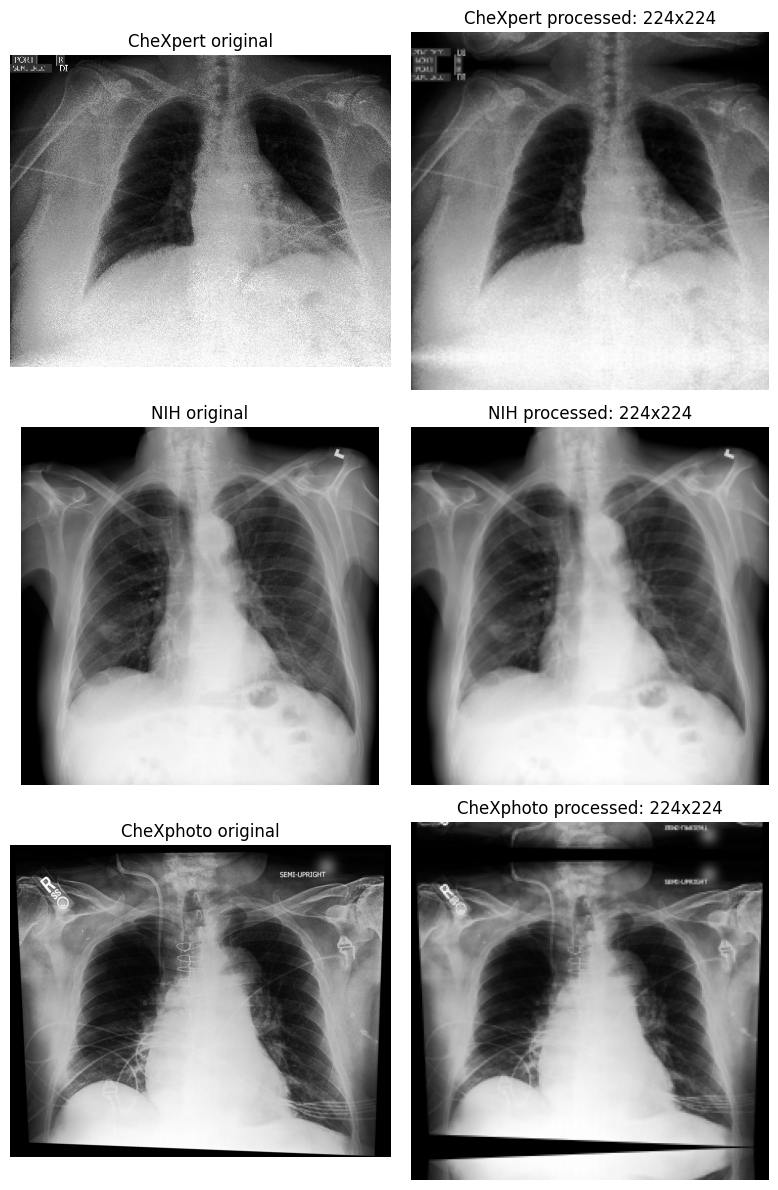

Visual before/after validation sample displayed.


In [17]:
distribution_rows = []
for dataset, paths in validation_sources.items():
    for image_path in paths:
        image = image_to_tensor_array(image_path)
        distribution_rows.append({
            'dataset': dataset,
            'mean': float(image.mean()),
            'std': float(image.std()),
            'near_zero_fraction': float((image <= 0.01).mean()),
            'near_one_fraction': float((image >= 0.99).mean()),
        })

preprocessed_distribution = pd.DataFrame(distribution_rows)
display(preprocessed_distribution.groupby('dataset').median().round(4))

visual_examples = [
    ('CheXpert', validation_sources['CheXpert'].iloc[0]),
    ('NIH', validation_sources['NIH'].iloc[0]),
    ('CheXphoto', validation_sources['CheXphoto'].iloc[0]),
]
fig, axes = plt.subplots(len(visual_examples), 2, figsize=(8, 4 * len(visual_examples)))
if len(visual_examples) == 1:
    axes = np.array([axes])
for row_index, (dataset, image_path) in enumerate(visual_examples):
    with Image.open(image_path) as image_file:
        original = np.asarray(image_file.convert('L'))
    processed = image_to_tensor_array(image_path)
    axes[row_index, 0].imshow(original, cmap='gray')
    axes[row_index, 0].set_title(f'{dataset} original')
    axes[row_index, 1].imshow(processed, cmap='gray', vmin=0, vmax=1)
    axes[row_index, 1].set_title(f'{dataset} processed: {IMAGE_SIZE}x{IMAGE_SIZE}')
    axes[row_index, 0].axis('off')
    axes[row_index, 1].axis('off')
plt.tight_layout()
plt.show()
print('Visual before/after validation sample displayed.')


## Image outlier review

In [18]:
outlier_rows = []
outlier_sources = {
    'CheXpert': chexpert_manifest['img_path'].dropna().drop_duplicates().head(100),
    'NIH': nih['img_path'].dropna().drop_duplicates().head(100),
    'CheXphoto': chexphoto_external['img_path'].dropna().drop_duplicates().head(100),
}

for dataset, paths in outlier_sources.items():
    metrics = quality_metrics_for_paths(paths, max_images=100)
    if metrics.empty:
        continue
    metrics['dataset'] = dataset
    outlier_rows.append(metrics)

outlier_metrics = pd.concat(outlier_rows, ignore_index=True)
outlier_metric_names = ['aspect', 'brightness', 'contrast', 'sharpness']
outlier_flags = []

for dataset, group in outlier_metrics.groupby('dataset', sort=False):
    group = group.copy()
    for metric in outlier_metric_names:
        lower = group[metric].quantile(0.01)
        upper = group[metric].quantile(0.99)
        group[f'{metric}_outlier'] = (
            group[metric].lt(lower) | group[metric].gt(upper)
        )
    flag_columns = [f'{metric}_outlier' for metric in outlier_metric_names]
    group['outlier_score'] = group[flag_columns].sum(axis=1)
    group['review_flag'] = group['outlier_score'].ge(2)
    outlier_flags.append(group)

outlier_metrics = pd.concat(outlier_flags, ignore_index=True)
display(outlier_metrics.groupby('dataset').agg(
    sampled_images=('img_path', 'size'),
    flagged_for_review=('review_flag', 'sum'),
    maximum_outlier_score=('outlier_score', 'max'),
))
display(outlier_metrics[outlier_metrics['review_flag']][[
    'dataset', 'img_path', 'outlier_score',
    'aspect', 'brightness', 'contrast', 'sharpness',
]].sort_values(['dataset', 'outlier_score'], ascending=[True, False]).head(20))


,sampled_images,flagged_for_review,maximum_outlier_score
dataset,,,
CheXpert,100,1,2
CheXphoto,100,1,2
NIH,100,0,1


,dataset,img_path,outlier_score,aspect,brightness,contrast,sharpness
4,CheXpert,/kaggle/input/datasets/ashery/chexpert/train/p...,2,1.0,114.049663,80.774377,1451.239990
281,CheXphoto,/kaggle/input/notebooks/t1f3001843/chexphoto-d...,2,1.0,124.125941,85.183367,536.842163


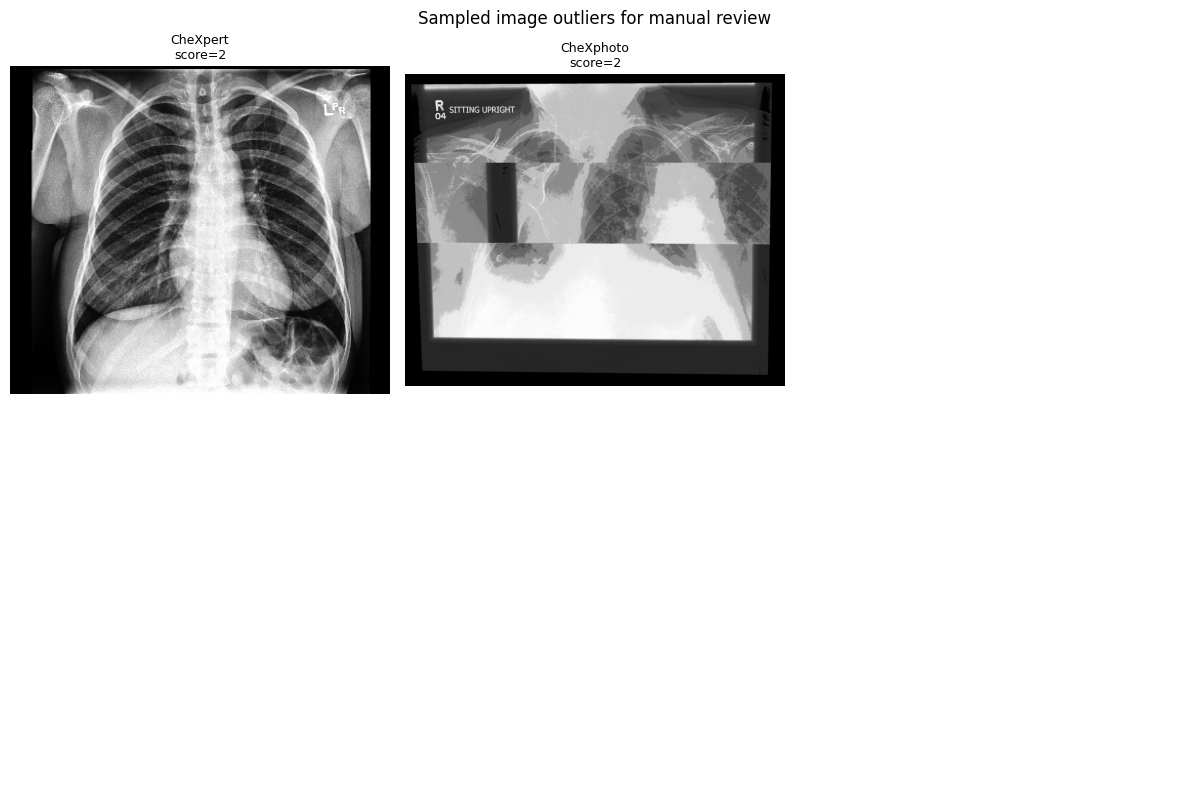

In [19]:
review_images = outlier_metrics[
    outlier_metrics['review_flag']
].drop_duplicates('img_path').head(6)

if not review_images.empty:
    fig, axes = plt.subplots(2, 3, figsize=(12, 8))
    for ax, (_, row) in zip(axes.flat, review_images.iterrows()):
        with Image.open(row['img_path']) as image_file:
            ax.imshow(image_file.convert('L'), cmap='gray')
        ax.set_title(
            f"{row['dataset']}\nscore={int(row['outlier_score'])}",
            fontsize=9,
        )
        ax.axis('off')
    for ax in axes.flat[len(review_images):]:
        ax.axis('off')
    plt.suptitle('Sampled image outliers for manual review')
    plt.tight_layout()
    plt.show()
else:
    print('No multi-metric image outliers were found in the sampled images.')


The outlier detection step performs quality control on a sample of images from each dataset: CheXpert, NIH, and CheXphoto. It does not automatically delete images because unusual images may represent important pathology or genuine photographic variation.

For every sampled image, the pipeline calculates four low-level image metrics:
* Aspect Ratio
* Brightness
* Contrast
* Sharpness

Images are evaluated separately within each dataset. For each metric, the bottom 1% and top 1% of values are treated as extreme values. An image is marked as an outlier for that metric if it falls outside this range.

The pipeline then calculates an outlier score by counting how many metrics flagged the image.

The purpose is to identify possible corrupted files, unusual acquisition conditions, extreme framing, blur, or exposure problems



,CheXpert train,CheXpert valid,NIH,CheXphoto,CheXpert train prevalence,NIH prevalence,selection score
Pleural Effusion,76899,64,13317,403,0.4026,0.1188,0.2187
Atelectasis,29720,75,11559,151,0.1556,0.1031,0.1266
Pneumothorax,17693,7,5302,92,0.0926,0.0473,0.0662
Lung Lesion,7040,1,11207,28,0.0369,0.1000,0.0607
Cardiomegaly,23385,66,2776,129,0.1224,0.0248,0.0551
Consolidation,12983,32,4667,67,0.0680,0.0416,0.0532


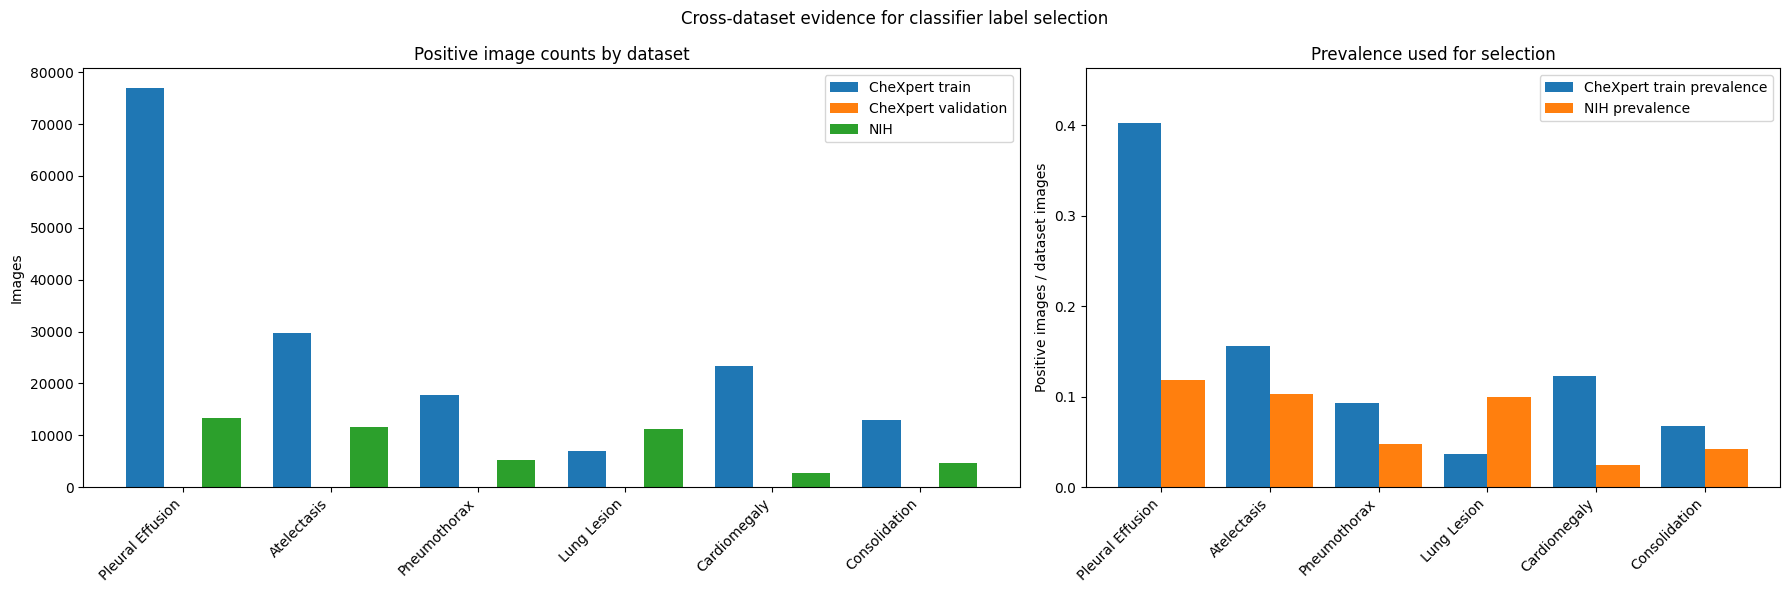

Selected classifier labels: ['Pleural Effusion', 'Atelectasis', 'Pneumothorax', 'Lung Lesion', 'Cardiomegaly', 'Consolidation']
Selection uses the geometric mean of CheXpert train and NIH image-level prevalence.


In [20]:
shared_label_names = list(CHEXPERT_SHARED_LABELS.values())
label_counts = pd.DataFrame(index=shared_label_names)
label_counts['CheXpert train'] = (
    chexpert_train[shared_label_names].eq(1).sum()
)
label_counts['CheXpert valid'] = (
    chexpert_valid[shared_label_names].eq(1).sum()
)

nih_positive_by_shared_label = {}
for label in shared_label_names:
    source_labels = [
        source_label for source_label, shared_label in NIH_TO_SHARED.items()
        if shared_label == label
    ]
    nih_positive_by_shared_label[label] = int(
        nih['Finding Labels'].fillna('').str.split('|').apply(
            lambda values: any(source_label in values for source_label in source_labels)
        ).sum()
    )
label_counts['NIH'] = pd.Series(nih_positive_by_shared_label)

if PHOTO_LABELS:
    photo_column_by_label = {
        column.replace('_', ' '): column for column in PHOTO_LABELS
    }
    label_counts['CheXphoto'] = pd.Series({
        label: int(
            chexphoto[photo_column_by_label[label]].eq(1).sum()
        ) if label in photo_column_by_label else np.nan
        for label in shared_label_names
    })

label_counts['CheXpert train prevalence'] = (
    label_counts['CheXpert train'] / len(chexpert_train)
)
label_counts['NIH prevalence'] = label_counts['NIH'] / len(nih)
label_counts['selection score'] = np.sqrt(
    label_counts['CheXpert train prevalence']
    * label_counts['NIH prevalence']
)
label_counts = label_counts.sort_values(
    ['selection score', 'CheXpert train'], ascending=False
)
display(label_counts.round(4))

plot_labels = label_counts.index
plot_positions = np.arange(len(plot_labels))
fig, (count_ax, prevalence_ax) = plt.subplots(
    1, 2, figsize=(18, 6), gridspec_kw={'width_ratios': [1.35, 1]}
)
count_width = 0.26
count_ax.bar(
    plot_positions - count_width,
    label_counts['CheXpert train'],
    width=count_width,
    label='CheXpert train',
)
count_ax.bar(
    plot_positions,
    label_counts['CheXpert valid'],
    width=count_width,
    label='CheXpert validation',
)
count_ax.bar(
    plot_positions + count_width,
    label_counts['NIH'],
    width=count_width,
    label='NIH',
)
count_ax.set_title('Positive image counts by dataset')
count_ax.set_ylabel('Images')
count_ax.set_xticks(plot_positions)
count_ax.set_xticklabels(plot_labels, rotation=45, ha='right')
count_ax.legend()

prevalence_ax.bar(
    plot_positions - 0.2,
    label_counts['CheXpert train prevalence'],
    width=0.4,
    label='CheXpert train prevalence',
)
prevalence_ax.bar(
    plot_positions + 0.2,
    label_counts['NIH prevalence'],
    width=0.4,
    label='NIH prevalence',
)
prevalence_ax.set_title('Prevalence used for selection')
prevalence_ax.set_ylabel('Positive images / dataset images')
prevalence_ax.set_xticks(plot_positions)
prevalence_ax.set_xticklabels(plot_labels, rotation=45, ha='right')
prevalence_ax.set_ylim(0, max(
    label_counts[['CheXpert train prevalence', 'NIH prevalence']]
    .max().max() * 1.15,
    0.01,
))
prevalence_ax.legend()
fig.suptitle('Cross-dataset evidence for classifier label selection')
plt.tight_layout()
plt.show()

N_SELECTED_LABELS = 6
CLASSIFICATION_LABELS = label_counts.head(N_SELECTED_LABELS).index.tolist()
print('Selected classifier labels:', CLASSIFICATION_LABELS)
print(
    'Selection uses the geometric mean of CheXpert train and NIH '
    'image-level prevalence.'
)


The shortlist is ranked by the geometric mean of CheXpert training prevalence and NIH prevalence, which favors abnormalities that are represented in both development datasets rather than being common in only one. The selected labels remain anatomically and semantically aligned with the NIH bounding-box supervision.

## Export

In [21]:
from pathlib import Path

nih_export_manifest = nih_localization_manifest[
    nih_localization_manifest['shared_label'].isin(CLASSIFICATION_LABELS)
].copy()

export_specs = [
    (chexpert_manifest, 'chexpert', CLASSIFICATION_LABELS),
    (nih_export_manifest, 'nih', [
        'shared_label', 'box_x', 'box_y', 'box_w', 'box_h'
    ]),
    (chexphoto_external, 'chexphoto_external', PHOTO_LABELS),
]

for manifest, name, labels in export_specs:
    valid = manifest['img_path'].apply(
        lambda p: Path(p).is_file()
    )

    print(
        f"{name}: {valid.sum():,} accessible / "
        f"{len(manifest):,} total | "
        f"{(~valid).sum():,} missing"
    )

    # Ensure original images aren't inside the directory we'll delete.
    for p in manifest.loc[valid, 'img_path'].head(10):
        source = Path(p).resolve()
        try:
            source.relative_to(EXPORT_ROOT.resolve())
            raise ValueError(
                f"Source image is inside export directory: {source}"
            )
        except ValueError as e:
            if str(e).startswith("Source image"):
                raise

chexpert: 191,229 accessible / 191,229 total | 0 missing


NameError: name 'EXPORT_ROOT' is not defined

In [ ]:
SHARD_SIZE = 512
IMAGE_SIZE = 224

def export_processed_manifest(manifest, name, label_columns):

    export_dir = EXPORT_ROOT / name
    export_dir.mkdir(parents=True, exist_ok=True)

    exported_rows = []

    batch = np.empty(
        (SHARD_SIZE, IMAGE_SIZE, IMAGE_SIZE),
        dtype=np.uint8
    )

    batch_metadata = []
    shard_number = 0
    batch_count = 0

    def save_shard():

        nonlocal shard_number, batch_count
        nonlocal batch_metadata, batch

        if batch_count == 0:
            return

        shard_path = export_dir / f'images_{shard_number:05d}.npy'

        # Save only the filled portion of the batch.
        np.save(shard_path, batch[:batch_count])

        for idx, metadata in enumerate(batch_metadata):

            exported_row = {
                'img_path': metadata['img_path'],
                'processed_path': str(shard_path),
                'shard_path': str(shard_path),
                'shard_index': idx,
                'source_row': metadata['source_row'],
            }

            exported_row.update(metadata['labels'])

            exported_rows.append(exported_row)

        print(
            f'{name}: saved shard {shard_number} '
            f'({batch_count} images)'
        )

        shard_number += 1
        batch_count = 0
        batch_metadata = []

    for row_number, (_, row) in enumerate(manifest.iterrows()):

        image_path = Path(row['img_path'])

        if not image_path.is_file():
            continue

        # Retain your existing preprocessing function.
        image = image_to_tensor_array(image_path)

        image = np.asarray(image, dtype=np.float32)

        if image.shape != (IMAGE_SIZE, IMAGE_SIZE):
            raise ValueError(
                f"Unexpected image shape {image.shape}: {image_path}"
            )

        # Convert normalized float32 to uint8.
        image = np.rint(
            np.clip(image, 0, 1) * 255
        ).astype(np.uint8)

        batch[batch_count] = image

        labels = {
            column: row[column]
            for column in label_columns
            if column in row.index
        }

        if 'split' in row.index:
            labels['split'] = row['split']

        if 'patient_id' in row.index:
            labels['patient_id'] = row['patient_id']

        batch_metadata.append({
            'img_path': str(image_path),
            'source_row': row_number,
            'labels': labels,
        })

        batch_count += 1

        if batch_count == SHARD_SIZE:
            save_shard()

    # Save the remaining images.
    save_shard()

    # Export metadata.
    exported_manifest = pd.DataFrame(exported_rows)

    manifest_path = EXPORT_ROOT / f'{name}_manifest.csv'

    exported_manifest.to_csv(
        manifest_path,
        index=False
    )

    print(
        f'\n{name}: {len(exported_manifest):,} images exported '
        f'into {shard_number} shards.'
    )

    return exported_manifest

In [ ]:
exported_chexpert = export_processed_manifest(
    chexpert_manifest,
    'chexpert',
    CLASSIFICATION_LABELS,
)

exported_nih = export_processed_manifest(
    nih_export_manifest,
    'nih',
    ['shared_label', 'box_x', 'box_y', 'box_w', 'box_h'],
)

exported_chexphoto = export_processed_manifest(
    chexphoto_external,
    'chexphoto_external',
    PHOTO_LABELS,
)

pd.Series(
    CLASSIFICATION_LABELS,
    name='label'
).to_csv(
    EXPORT_ROOT / 'classification_labels.csv',
    index=False
)

print(f'\nProcessed export directory: {EXPORT_ROOT}')